# RAPPORT COMPLET
## Analyse financière de 8. Banque Agricole du Faso (BADF) — Burkina Faso
**Burkina Faso · Exercices 2021 à 2023 · Montants en millions FCFA**

Source des données : *Fascicule BCEAO des bilans et comptes de résultat des banques de l’UMOA 2023 / Base Excel (Bilans_et_Comptes_de_Resultat_Exhaustif.xlsx)*

---

## 1. Synthèse et points clés
Cette première partie présente une vue d’ensemble de la situation financière de la banque avant l’analyse détaillée.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

# Palette et typographie du rapport
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8
plt.rcParams['figure.facecolor'] = 'white'

# Le fichier est recherche dans le dossier courant puis dans ses dossiers parents
excel_name = 'Bilans_et_Comptes_de_Resultat_Exhaustif.xlsx'
search_dirs = [Path.cwd(), *Path.cwd().parents]
excel_matches = [folder / excel_name for folder in search_dirs if (folder / excel_name).exists()]
if not excel_matches:
    local_excels = list(Path.cwd().glob('*.xlsx'))
    if len(local_excels) == 1:
        excel_matches = local_excels
if not excel_matches:
    raise FileNotFoundError(
        f"Classeur introuvable : {excel_name}. Placez-le dans le dossier du projet ou adaptez excel_name."
    )
excel_path = excel_matches[0]

sheet_name = 'Toutes_Les_Donnees'
df_all = pd.read_excel(excel_path, sheet_name=sheet_name)
required_columns = {'CODE BANQUE', 'POSTE / RUBRIQUE'}
missing_columns = required_columns.difference(df_all.columns)
if missing_columns:
    raise ValueError(f"Colonnes absentes du classeur : {sorted(missing_columns)}")

df_all['CODE BANQUE'] = df_all['CODE BANQUE'].astype('string').str.strip().str.upper()
df_all['_RUBRIQUE_NORM'] = df_all['POSTE / RUBRIQUE'].astype(str).str.strip().str.upper()

# Choisir ici un code parmi ceux affiches (BADF par defaut)
available_banks = sorted(df_all['CODE BANQUE'].dropna().unique().tolist())
print(f"Codes banques disponibles : {', '.join(available_banks)}")
bank_code = 'BADF'
df_bank = df_all.loc[df_all['CODE BANQUE'] == bank_code.upper()].copy()
if df_bank.empty:
    raise ValueError(f"Banque {bank_code!r} absente. Codes disponibles : {available_banks}")

years = [str(year) for year in (2021, 2022, 2023) if str(year) in df_bank.columns]
if not years:
    raise ValueError('Aucune colonne annuelle 2021-2023 n’a ete trouvee dans le classeur.')

# Valeurs manquantes ou marquees '-' restent numeriquement nulles

def get_val(rubrique, year):
    key = str(rubrique).strip().upper()
    rows = df_bank.loc[df_bank['_RUBRIQUE_NORM'] == key, year]
    if rows.empty:
        return 0.0
    value = pd.to_numeric(rows.iloc[0], errors='coerce')
    return float(value) if pd.notna(value) else 0.0


def safe_ratio(numerator, denominator, scale=100):
    if denominator is None or not np.isfinite(denominator) or denominator == 0:
        return np.nan
    return numerator / denominator * scale


# Postes de bilan et du compte de resultat disponibles dans le fichier
postes = {
    'total_actif': "TOTAL DE L'ACTIF",
    'total_passif': 'TOTAL DU PASSIF',
    'creances_clientele': 'CREANCES SUR LA CLIENTELE',
    'depots_clientele': "DETTES A L'EGARD DE LA CLIENTELE",
    'dettes_interbank': 'DETTES INTERBANCAIRES ET ASSIMILEES',
    'caisse_bceao': 'CAISSE, BANQUE CENTRALE, CCP',
    'creances_interbank': 'CREANCES INTERBANCAIRES ET ASSIMILEES',
    'effets_publics': 'EFFETS PUBLICS ET VALEURS ASSIMILEES',
    'equity': 'CAPITAUX PROPRES ET RESSOURCES ASSIMILEES',
    'resultat_net': 'RESULTAT NET',
    'pnb': 'PRODUITS NET BANCAIRE',
    'charges_exploitation': "CHARGES GENERALES D'EXPLOITATION",
    'amortissements': 'DOTATIONS AUX AMORTISSEMENTS ET AUX DEPRECIATIONS DES IMMOBILISATIONS INCOPORELLES ET CORPORELLES',
    'cout_risque': 'COUT DU RISQUE',
    'interets_produits': 'INTERETS ET PRODUITS ASSIMILEES',
    'interets_charges': 'INTERETS ET CHARGES ASSIMILEES',
    'commissions_produits': 'COMMISSIONS (PRODUITS)',
    'commissions_charges': 'COMMISSIONS (CHARGES)',
    'subventions': 'SUBVENTIONS D\'INVESTISSEMENT',
    'gains_actifs_immobilises': 'GAINS OU PERTES NETS SUR ACTIFS IMMOBILISES (+/-)',
    'resultat_brut_exploitation': 'RESULTAT BRUT D\'EXPLOITATION',
    'resultat_exploitation': 'RESULTAT D\'EXPLOITATION',
}
valeurs = {nom: {year: get_val(poste, year) for year in years} for nom, poste in postes.items()}

# Variables historiques conservees pour la suite du rapport
for nom, values in valeurs.items():
    globals()[nom] = values
capitaux_propres = equity

print(f"Donnees chargees : {bank_code} | {excel_path.name} | {', '.join(years)}")
print(f"Postes de la banque : {len(df_bank)}")

Codes banques disponibles : BADF, BCB, BHS, BPBF, CDS, FBNBANK, IB BANK, WBI
Donnees chargees : BADF | Bilans_et_Comptes_de_Resultat_Exhaustif.xlsx | 2021, 2022, 2023
Postes de la banque : 61


In [3]:
from IPython.display import HTML, display

REPORT_TABLE_STYLES = [
    {'selector': 'table', 'props': [('border-collapse', 'collapse'), ('width', '100%'), ('color', '#e7eee9'), ('font-family', 'DejaVu Sans, sans-serif')]},
    {'selector': 'thead th', 'props': [('background-color', '#39433d'), ('color', '#f4f7f5'), ('padding', '7px'), ('text-align', 'right'), ('border-bottom', '2px solid #82c49b')]},
    {'selector': 'tbody td', 'props': [('background-color', '#292e2b'), ('color', '#e7eee9'), ('border-bottom', '1px solid #4b554f'), ('padding', '6px'), ('text-align', 'right')]},
    {'selector': 'tbody th', 'props': [('background-color', '#343c37'), ('color', '#a7d8bd'), ('border-bottom', '1px solid #4b554f'), ('padding', '6px'), ('text-align', 'left')]},
]


def style_report_table(dataframe, formatters=None):
    return (
        dataframe.style
        .format(formatters or {}, na_rep='—')
        .set_table_styles(REPORT_TABLE_STYLES)
        .set_properties(**{'vertical-align': 'top'})
    )


plt.rcParams.update({
    'axes.facecolor': '#f7f9f7',
    'axes.titlecolor': '#26332b',
    'axes.labelcolor': '#39433d',
    'xtick.color': '#39433d',
    'ytick.color': '#39433d',
    'grid.color': '#d9dfdb',
    'grid.linewidth': 0.7,
})

## 2. Dynamique du bilan et du compte de résultat

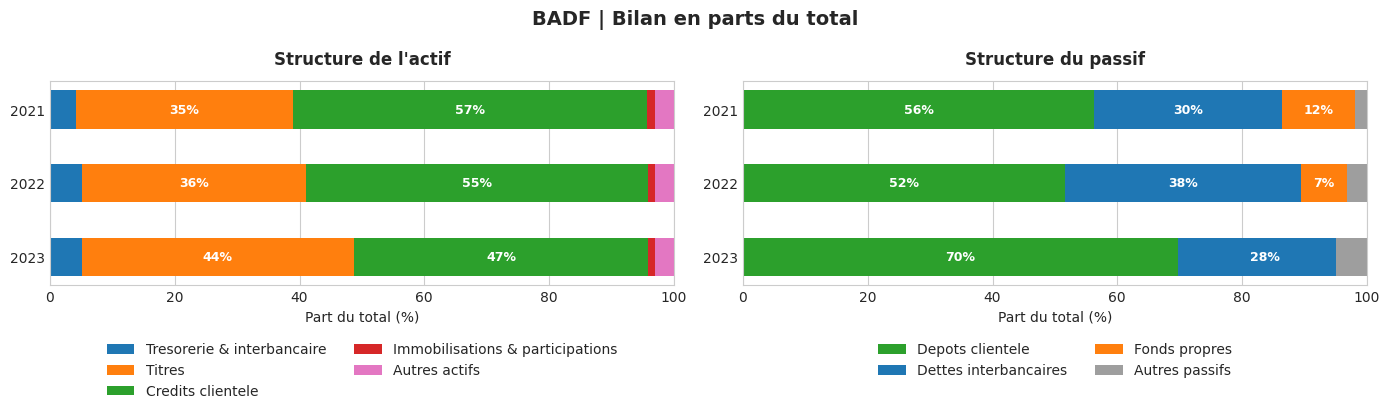

Actif (%)                           \
     Tresorerie & interbancaire Titres Credits clientele   
2021                       4.15  34.84             56.70   
2022                       5.09  35.88             54.97   
2023                       5.09  43.65             47.16   

                                                          Passif (%)  \
     Immobilisations & participations Autres actifs Depots clientele   
2021                             1.21          3.10            56.29   
2022                             0.98          3.08            51.56   
2023                             1.05          3.05            69.67   

                                                         
     Dettes interbancaires Fonds propres Autres passifs  
2021                 30.16         11.70           1.85  
2022                 37.82          7.45           3.16  
2023                 27.90         -2.45           4.88

In [ ]:
# Figures 1 et 2 : structure de l'actif et du passif
categories_actif = [
    'Tresorerie & interbancaire', 'Titres', 'Credits clientele',
    'Immobilisations & participations', 'Autres actifs'
]
colors_actif = ['#427f75', '#cf9d4c', '#629b74', '#ba6b61', '#8e9b91']
categories_passif = ['Depots clientele', 'Dettes interbancaires', 'Fonds propres', 'Autres passifs']
colors_passif = ['#629b74', '#427f75', '#cf9d4c', '#8e9b91']

data_actif = []
data_passif = []
for year in years:
    tresorerie = caisse_bceao[year] + creances_interbank[year]
    titres = (
        effets_publics[year]
        + get_val('OBLIGATIONS ET AUTRES TITRES A REVENU FIXE', year)
        + get_val('ACTIONS ET AUTRES TITRES A REVENU VARIABLE', year)
    )
    immobilisations = sum(get_val(poste, year) for poste in [
        'IMMOBILISATIONS CORPORELLES',
        'IMMOBILISATIONS INCORPORELLES',
        'PARTICIPATIONS ET AUTRES TITRES DETENUS A LONG TERME',
        'PARTS DANS LES ENTREPRISES LIEES',
    ])
    actif_autres = total_actif[year] - (tresorerie + titres + creances_clientele[year] + immobilisations)
    data_actif.append([
        safe_ratio(tresorerie, total_actif[year]),
        safe_ratio(titres, total_actif[year]),
        safe_ratio(creances_clientele[year], total_actif[year]),
        safe_ratio(immobilisations, total_actif[year]),
        safe_ratio(actif_autres, total_actif[year]),
    ])

    passif_autres = total_passif[year] - (
        depots_clientele[year] + dettes_interbank[year] + capitaux_propres[year]
    )
    data_passif.append([
        safe_ratio(depots_clientele[year], total_passif[year]),
        safe_ratio(dettes_interbank[year], total_passif[year]),
        safe_ratio(capitaux_propres[year], total_passif[year]),
        safe_ratio(passif_autres, total_passif[year]),
    ])

df_pct_actif = pd.DataFrame(data_actif, index=years, columns=categories_actif).fillna(0)
df_pct_passif = pd.DataFrame(data_passif, index=years, columns=categories_passif).fillna(0)
df_structure = pd.concat({'Actif (%)': df_pct_actif, 'Passif (%)': df_pct_passif}, axis=1)


def draw_stacked_structure(axis, data, categories, colors, title):
    left = np.zeros(len(years))
    for category, color in zip(categories, colors):
        values = data[category].to_numpy(dtype=float)
        axis.barh(years, values, left=left, label=category, color=color, height=0.52)
        for index, value in enumerate(values):
            if value >= 6:
                axis.text(left[index] + value / 2, index, f'{value:.0f}%', ha='center', va='center', color='white', fontweight='bold', fontsize=9)
        left += values
    axis.set_title(title, fontsize=12, fontweight='bold', pad=12)
    axis.set_xlim(0, 100)
    axis.set_xlabel('Part du total (%)')
    axis.invert_yaxis()
    axis.grid(axis='x', alpha=0.55)
    axis.set_axisbelow(True)


fig, (ax_actif, ax_passif) = plt.subplots(1, 2, figsize=(14, 4.5))
draw_stacked_structure(ax_actif, df_pct_actif, categories_actif, colors_actif, "Structure de l'actif")
draw_stacked_structure(ax_passif, df_pct_passif, categories_passif, colors_passif, 'Structure du passif')
ax_actif.legend(loc='upper center', bbox_to_anchor=(0.5, -0.22), ncol=2, frameon=False)
ax_passif.legend(loc='upper center', bbox_to_anchor=(0.5, -0.22), ncol=2, frameon=False)
fig.suptitle(f'{bank_code} | Bilan en parts du total', fontsize=14, fontweight='bold', color='#26332b')
plt.tight_layout()
plt.show()

percentage_formatters = {column: '{:.2f} %' for column in df_structure.columns}
display(style_report_table(df_structure.round(2), formatters=percentage_formatters))

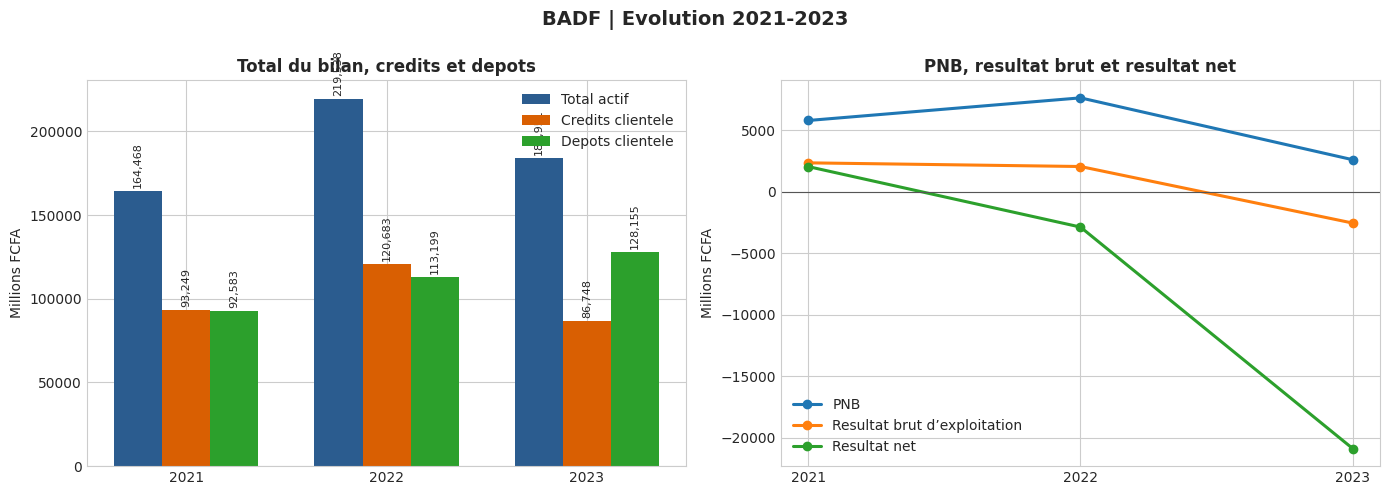

,2021,2022,2023,Variation 2021-2022 (%),Variation 2022-2023 (%)
Total actif,164468,219538,183951,33.5,-16.2
Total passif,164468,219536,183949,33.5,-16.2
Credits clientele,93249,120683,86748,29.4,-28.1
Depots clientele,92583,113199,128155,22.3,13.2
PNB,5773,7611,2586,31.8,-66.0
Resultat brut d’exploitation,2334,2036,-2557,-12.8,-225.6
Resultat net,2030,-2882,-20870,-242.0,624.1


In [4]:
# Figures 3 et 4 : bilan, credits, depots et resultats
fig, (ax_bilan, ax_resultats) = plt.subplots(1, 2, figsize=(14, 5))
x = np.arange(len(years))
width = 0.24
series_bilan = {
    'Total actif': total_actif,
    'Credits clientele': creances_clientele,
    'Depots clientele': depots_clientele,
}
colors_bilan = ['#2b5c8f', '#d95f02', '#2ca02c']
for offset, ((label, values), color) in enumerate(zip(series_bilan.items(), colors_bilan)):
    bars = ax_bilan.bar(x + (offset - 1) * width, [values[year] for year in years], width, label=label, color=color)
    ax_bilan.bar_label(bars, labels=[f'{bar.get_height():,.0f}' for bar in bars], padding=2, fontsize=8, rotation=90)
ax_bilan.set_title('Total du bilan, credits et depots', fontsize=12, fontweight='bold')
ax_bilan.set_ylabel('Millions FCFA')
ax_bilan.set_xticks(x, years)
ax_bilan.legend(frameon=False)

resultat_net_compte = {year: get_val('RESULTAT NET', year) for year in years}
series_resultats = {
    'PNB': pnb,
    'Resultat brut d’exploitation': resultat_brut_exploitation,
    'Resultat net': resultat_net_compte,
}
for label, values in series_resultats.items():
    ax_resultats.plot(years, [values[year] for year in years], marker='o', linewidth=2.2, markersize=6, label=label)
ax_resultats.axhline(0, color='#555555', linewidth=0.8)
ax_resultats.set_title('PNB, resultat brut et resultat net', fontsize=12, fontweight='bold')
ax_resultats.set_ylabel('Millions FCFA')
ax_resultats.legend(frameon=False)
fig.suptitle(f'{bank_code} | Evolution 2021-2023', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

montants_bilan = pd.DataFrame({
    'Total actif': total_actif,
    'Total passif': total_passif,
    'Credits clientele': creances_clientele,
    'Depots clientele': depots_clientele,
    'PNB': pnb,
    'Resultat brut d’exploitation': resultat_brut_exploitation,
    'Resultat net': resultat_net_compte,
}, index=years).T
variations = montants_bilan.pct_change(axis=1) * 100
display(montants_bilan.round(0).astype('int64').assign(**{
    f'Variation {years[i-1]}-{years[i]} (%)': variations[years[i]].round(1)
    for i in range(1, len(years))
}))

## 3. Ratios de structure
Transformation, liquidité, levier et solvabilité.

Ratios de structure, rentabilite et efficacite (en %, sauf multiplicateur)


,Formule,Reference,2021,2022,2023,Statut 2023
Ratio,,,,,,
Transformation,Credits clientele / depots clientele,Maximum 100 %,100.72,106.61,67.69,Conforme
Liquidite du bilan (proxy),(caisse + interbancaire + effets publics) / re...,Repere 30 %; approximation sans echeances,45.11,45.83,49.95,Conforme
Solvabilite comptable (proxy),Capitaux propres et ressources assimilees / to...,Repere indicatif 8 %,11.70,7.45,-2.45,Sous le repere
Solvabilite globale reglementaire,Fonds propres effectifs / actifs ponderes des ...,"Minimum 11,5 %; RWA absents",NaN,NaN,NaN,Non calculable
CET1,Fonds propres CET1 / actifs ponderes des risques,"Minimum 7,5 %; CET1 et RWA absents",NaN,NaN,NaN,Non calculable
Tier 1,Fonds propres Tier 1 / actifs ponderes des ris...,"Minimum 8,5 %; Tier 1 et RWA absents",NaN,NaN,NaN,Non calculable
Levier reglementaire,Tier 1 / exposition totale,Minimum 3 %; Tier 1 absent,NaN,NaN,NaN,Non calculable
ROA,Resultat net / total actif,Repere 1 %,1.23,-1.31,-11.35,Sous le repere
ROE,Resultat net / capitaux propres,Repere 10 %,10.55,-17.61,462.95,Non interpretable : fonds propres <= 0


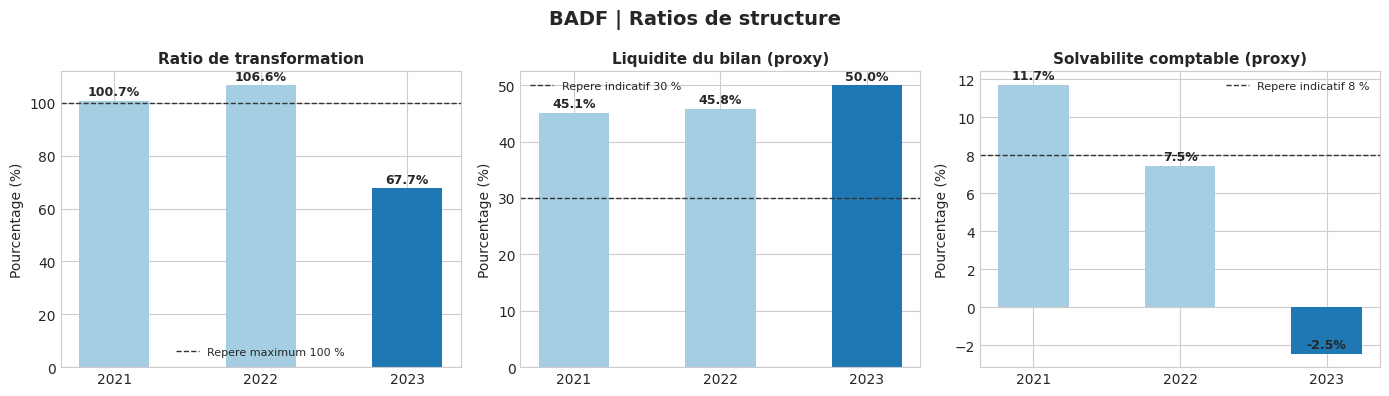

In [11]:
# Ratios de structure et de liquidite
transfo = {year: safe_ratio(creances_clientele[year], depots_clientele[year]) for year in years}
actifs_liquides_proxy = {
    year: caisse_bceao[year] + creances_interbank[year] + effets_publics[year]
    for year in years
}
ressources_exigibles_proxy = {
    year: get_val('BANQUES CENTRALES, CCP', year)
    + dettes_interbank[year] + depots_clientele[year]
    for year in years
}
liquidite_bilan_proxy = {
    year: safe_ratio(actifs_liquides_proxy[year], ressources_exigibles_proxy[year])
    for year in years
}
solvabilite_bilan = {
    year: safe_ratio(capitaux_propres[year], total_actif[year])
    for year in years
}

# Ratios de rentabilite et d'efficacite calcules depuis les postes du classeur
roa = {year: safe_ratio(resultat_net[year], total_actif[year]) for year in years}
roe = {year: safe_ratio(resultat_net[year], capitaux_propres[year]) for year in years}
multiplicateur = {
    year: safe_ratio(total_actif[year], capitaux_propres[year], scale=1)
    for year in years
}
ratio_cout_exploitation = {
    year: safe_ratio(charges_exploitation[year] + amortissements[year], pnb[year])
    for year in years
}
ratio_cout_risque = {
    year: safe_ratio(cout_risque[year], creances_clientele[year])
    for year in years
}
marge_nette = {year: safe_ratio(resultat_net[year], pnb[year]) for year in years}
marge_interets_pnb = {
    year: safe_ratio(interets_produits[year] - interets_charges[year], pnb[year])
    for year in years
}
commissions_nettes_pnb = {
    year: safe_ratio(commissions_produits[year] - commissions_charges[year], pnb[year])
    for year in years
}
pnb_actif = {year: safe_ratio(pnb[year], total_actif[year]) for year in years}

ratio_values = {
    'Transformation': (transfo, 'Credits clientele / depots clientele', 'Maximum 100 %'),
    'Liquidite du bilan (proxy)': (liquidite_bilan_proxy, '(caisse + interbancaire + effets publics) / ressources exigibles', 'Repere 30 %; approximation sans echeances'),
    'Solvabilite comptable (proxy)': (solvabilite_bilan, 'Capitaux propres et ressources assimilees / total actif', 'Repere indicatif 8 %'),
    'Solvabilite globale reglementaire': ({year: np.nan for year in years}, 'Fonds propres effectifs / actifs ponderes des risques', 'Minimum 11,5 %; RWA absents'),
    'CET1': ({year: np.nan for year in years}, 'Fonds propres CET1 / actifs ponderes des risques', 'Minimum 7,5 %; CET1 et RWA absents'),
    'Tier 1': ({year: np.nan for year in years}, 'Fonds propres Tier 1 / actifs ponderes des risques', 'Minimum 8,5 %; Tier 1 et RWA absents'),
    'Levier reglementaire': ({year: np.nan for year in years}, 'Tier 1 / exposition totale', 'Minimum 3 %; Tier 1 absent'),
    'ROA': (roa, 'Resultat net / total actif', 'Repere 1 %'),
    'ROE': (roe, 'Resultat net / capitaux propres', 'Repere 10 %'),
    'Multiplicateur Du Pont': (multiplicateur, 'Total actif / capitaux propres', 'Sans seuil'),
    'Cout d’exploitation / PNB': (ratio_cout_exploitation, '(charges generales + amortissements) / PNB', 'Repere maximum 60 %'),
    'Cout du risque / credits': (ratio_cout_risque, 'Cout du risque / credits clientele', 'Repere maximum 2 %'),
    'Marge nette': (marge_nette, 'Resultat net / PNB', 'Sans seuil'),
    'Marge nette d’interets / PNB': (marge_interets_pnb, '(produits d’interets - charges d’interets) / PNB', 'Sans seuil'),
    'Commissions nettes / PNB': (commissions_nettes_pnb, '(commissions produits - commissions charges) / PNB', 'Sans seuil'),
    'PNB / total actif': (pnb_actif, 'PNB / total actif', 'Sans seuil'),
}


def ratio_status(value, reference):
    if not np.isfinite(value):
        return 'Non calculable'
    if 'Maximum' in reference or 'maximum' in reference:
        limit = float(reference.split('%', 1)[0].replace(',', '.').split()[-1])
        return 'Conforme' if value <= limit else 'A surveiller'
    if 'Repere' in reference or 'Minimum' in reference:
        limit = float(reference.split('%', 1)[0].replace(',', '.').split()[-1])
        return 'Conforme' if value >= limit else 'Sous le repere'
    return 'Information'

rows = []
for label, (values, formula, reference) in ratio_values.items():
    row = {'Ratio': label, 'Formule': formula, 'Reference': reference}
    row.update({year: values[year] for year in years})
    row['Statut ' + years[-1]] = ratio_status(values[years[-1]], reference)
    rows.append(row)
df_ratios = pd.DataFrame(rows).set_index('Ratio')
if capitaux_propres[years[-1]] <= 0:
    df_ratios.loc['ROE', 'Statut ' + years[-1]] = 'Non interpretable : fonds propres <= 0'
print('Ratios de structure, rentabilite et efficacite (en %, sauf multiplicateur)')
display(df_ratios.round(2))

# Courbes des principaux ratios de structure
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
ratio_charts = [
    (transfo, 'Ratio de transformation', 'Repere maximum 100 %', 100),
    (liquidite_bilan_proxy, 'Liquidite du bilan (proxy)', 'Repere indicatif 30 %', 30),
    (solvabilite_bilan, 'Solvabilite comptable (proxy)', 'Repere indicatif 8 %', 8),
]
for axis, (values, title, reference_label, reference_value) in zip(axes, ratio_charts):
    plotted = [values[year] for year in years]
    bars = axis.bar(years, plotted, color=['#a6cee3', '#a6cee3', '#1f78b4'], width=0.48)
    axis.axhline(reference_value, color='#333333', linestyle='--', linewidth=1, label=reference_label)
    axis.set_title(title, fontsize=11, fontweight='bold')
    axis.set_ylabel('Pourcentage (%)')
    axis.legend(frameon=False, fontsize=8)
    for bar, value in zip(bars, plotted):
        if np.isfinite(value):
            axis.annotate(f'{value:.1f}%', (bar.get_x() + bar.get_width() / 2, value), xytext=(0, 4), textcoords='offset points', ha='center', fontsize=9, fontweight='bold')
fig.suptitle(f'{bank_code} | Ratios de structure', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

In [ ]:
indicateurs_exploitation = [
    'Marge nette',
    'Cout d’exploitation / PNB',
    'Cout du risque / credits',
    'Marge nette d’interets / PNB',
    'Commissions nettes / PNB',
    'PNB / total actif',
]
df_indicateurs_exploitation = df_ratios.loc[indicateurs_exploitation].rename(
    index={'Cout d’exploitation / PNB': 'Coefficient d’exploitation'}
)
print('Indicateurs d’exploitation (en %, sauf indication contraire)')
display(df_indicateurs_exploitation.round(2))

## 4. Rentabilité : ROA, ROE et effet de levier

Attention : le ROE 2023 est mathematiquement calcule, mais non interpretable car les fonds propres sont negatifs.


,Formule,2021,2022,2023,Statut 2023
Ratio,,,,,
ROE,Resultat net / capitaux propres,10.547646,-17.613984,462.954747,Non interpretable : fonds propres <= 0


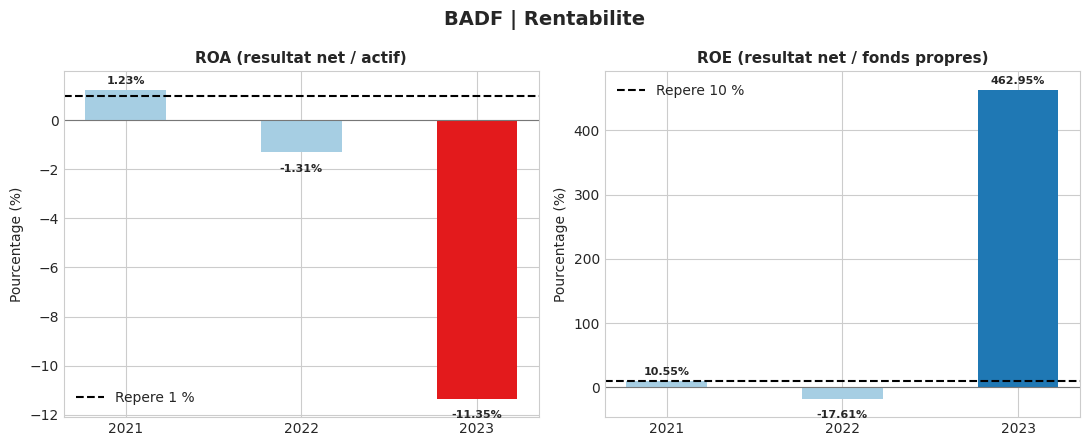

Decomposition Du Pont : ROE = ROA x multiplicateur (attention si les fonds propres sont negatifs).


,ROA (%),Multiplicateur (x),ROE comptable (%),Capitaux propres (millions FCFA)
2021,1.23,8.55,10.55,19246.0
2022,-1.31,13.42,-17.61,16362.0
2023,-11.35,-40.81,462.95,-4508.0


In [12]:
# ROA, ROE et decomposition Du Pont
if capitaux_propres[years[-1]] <= 0:
    df_ratios.loc['ROE', 'Statut ' + years[-1]] = 'Non interpretable : fonds propres <= 0'
    print(f"Attention : le ROE {years[-1]} est mathematiquement calcule, mais non interpretable car les fonds propres sont negatifs.")
    display(df_ratios.loc[['ROE'], ['Formule', *years, 'Statut ' + years[-1]]])

fig, (ax_roa, ax_roe) = plt.subplots(1, 2, figsize=(11, 4.5))
for axis, values, title, benchmark, color in [
    (ax_roa, roa, 'ROA (resultat net / actif)', 1.0, '#e31a1c'),
    (ax_roe, roe, 'ROE (resultat net / fonds propres)', 10.0, '#1f78b4'),
]:
    plotted = [values[year] for year in years]
    bars = axis.bar(years, plotted, color=['#a6cee3', '#a6cee3', color], width=0.46)
    axis.axhline(benchmark, color='black', linestyle='--', label=f'Repere {benchmark:g} %')
    axis.axhline(0, color='#777777', linewidth=0.8)
    axis.set_title(title, fontsize=11, fontweight='bold')
    axis.set_ylabel('Pourcentage (%)')
    axis.legend(frameon=False)
    span = max(max(plotted), benchmark) - min(min(plotted), 0)
    padding = max(span * 0.06, 0.5)
    axis.set_ylim(min(min(plotted), 0) - padding, max(max(plotted), benchmark) + padding)
    for bar, value in zip(bars, plotted):
        axis.annotate(f'{value:.2f}%', (bar.get_x() + bar.get_width() / 2, value), xytext=(0, 4 if value >= 0 else -14), textcoords='offset points', ha='center', fontsize=8, fontweight='bold')
fig.suptitle(f'{bank_code} | Rentabilite', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

df_dupont = pd.DataFrame({
    'ROA (%)': [roa[year] for year in years],
    'Multiplicateur (x)': [multiplicateur[year] for year in years],
    'ROE comptable (%)': [roe[year] for year in years],
    'Capitaux propres (millions FCFA)': [capitaux_propres[year] for year in years],
}, index=years)
print('Decomposition Du Pont : ROE = ROA x multiplicateur (attention si les fonds propres sont negatifs).')
display(df_dupont.round(2))

## 5. Test de faillite et ratios de stress
Évaluation de la capacité d'absorption des risques.

Stress tests calcules a partir des postes disponibles; valeurs en millions FCFA sauf ratios.
Le seuil de perte reglementaire reste indisponible faute de donnees sur les actifs ponderes des risques.


,2021,2022,2023
Perte d’actifs absorbable (%),11.70,7.45,-2.45
Defauts de credits absorbables (%),20.64,13.56,-5.20
Perte nette critique (millions FCFA),-19246.00,-16362.00,4508.00
PNB critique (millions FCFA),-15547.00,-5942.00,27898.00
Baisse du PNB tolerable (%),369.31,178.07,-978.81
Cout du risque critique (millions FCFA),21580.00,18398.00,-7065.00
Perte avant seuil de solvabilite (millions FCFA),NaN,NaN,NaN


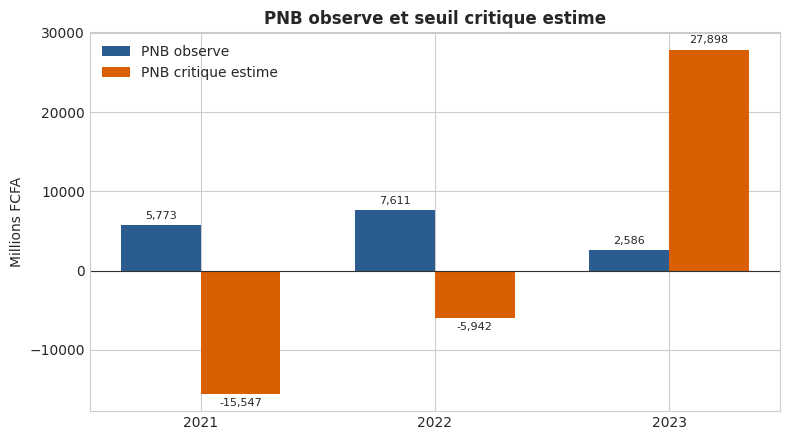

In [8]:
# Stress test : capacite d'absorption et seuil de rentabilite
perte_actifs_absorbable = {
    year: safe_ratio(capitaux_propres[year], total_actif[year])
    for year in years
}
defauts_credits_absorbables = {
    year: safe_ratio(capitaux_propres[year], creances_clientele[year])
    for year in years
}
perte_nette_critique = {year: -capitaux_propres[year] for year in years}
pnb_critique = {
    year: (
        -capitaux_propres[year]
        - subventions[year]
        + charges_exploitation[year]
        + amortissements[year]
        + cout_risque[year]
        - gains_actifs_immobilises[year]
    )
    for year in years
}
baisse_pnb_tolerable = {
    year: safe_ratio(pnb[year] - pnb_critique[year], pnb[year])
    for year in years
}
cout_risque_critique = {
    year: (
        pnb[year]
        + subventions[year]
        - charges_exploitation[year]
        - amortissements[year]
        + gains_actifs_immobilises[year]
        + capitaux_propres[year]
    )
    for year in years
}

# Le ratio de perte avant non-respect du seuil de solvabilite exige les RWA
perte_avant_seuil_solvabilite = {year: np.nan for year in years}

stress_data = {
    'Perte d’actifs absorbable (%)': perte_actifs_absorbable,
    'Defauts de credits absorbables (%)': defauts_credits_absorbables,
    'Perte nette critique (millions FCFA)': perte_nette_critique,
    'PNB critique (millions FCFA)': pnb_critique,
    'Baisse du PNB tolerable (%)': baisse_pnb_tolerable,
    'Cout du risque critique (millions FCFA)': cout_risque_critique,
    'Perte avant seuil de solvabilite (millions FCFA)': perte_avant_seuil_solvabilite,
}
df_stress = pd.DataFrame(stress_data, index=years).T
print('Stress tests calcules a partir des postes disponibles; valeurs en millions FCFA sauf ratios.')
print('Le seuil de perte reglementaire reste indisponible faute de donnees sur les actifs ponderes des risques.')
display(df_stress.round(2))

fig, ax = plt.subplots(figsize=(8, 4.5))
x = np.arange(len(years))
width = 0.34
bars_pnb = ax.bar(x - width / 2, [pnb[year] for year in years], width, label='PNB observe', color='#2b5c8f')
bars_critique = ax.bar(x + width / 2, [pnb_critique[year] for year in years], width, label='PNB critique estime', color='#d95f02')
ax.axhline(0, color='#333333', linewidth=0.8)
ax.set_xticks(x, years)
ax.set_ylabel('Millions FCFA')
ax.set_title('PNB observe et seuil critique estime', fontsize=12, fontweight='bold')
ax.legend(frameon=False)
for bars in (bars_pnb, bars_critique):
    ax.bar_label(bars, labels=[f'{bar.get_height():,.0f}' for bar in bars], padding=3, fontsize=8)
plt.tight_layout()
plt.show()

## 6. Bâle III : solvabilité réglementaire et liquidité
Le classeur Excel ne contient ni actifs pondérés des risques (RWA), ni détail CET1/Tier 1, ni échéancier des actifs et passifs, ni sorties nettes de trésorerie à 30 jours. Les ratios réglementaires correspondants sont donc présentés avec leur seuil de référence, mais sans valeur inventée. La liquidité calculée plus haut est une approximation de bilan, pas un LCR réglementaire.

In [9]:
# Ratios et donnees reglementaires absents du classeur
indicateurs_bale = pd.DataFrame([
    {
        'Indicateur': 'Solvabilite globale',
        'Formule': 'Fonds propres effectifs / RWA',
        'Seuil de reference': '11,5 %',
        'Donnees manquantes': 'Fonds propres effectifs et actifs ponderes des risques',
        'Statut': 'Non calculable',
    },
    {
        'Indicateur': 'CET1',
        'Formule': 'Fonds propres CET1 / RWA',
        'Seuil de reference': '7,5 %',
        'Donnees manquantes': 'Capital CET1 et actifs ponderes des risques',
        'Statut': 'Non calculable',
    },
    {
        'Indicateur': 'Tier 1',
        'Formule': 'Fonds propres Tier 1 / RWA',
        'Seuil de reference': '8,5 %',
        'Donnees manquantes': 'Capital Tier 1 et actifs ponderes des risques',
        'Statut': 'Non calculable',
    },
    {
        'Indicateur': 'Ratio de levier reglementaire',
        'Formule': 'Capital Tier 1 / exposition totale',
        'Seuil de reference': '3 %',
        'Donnees manquantes': 'Capital Tier 1 et exposition reglementaire',
        'Statut': 'Non calculable',
    },
    {
        'Indicateur': 'Couverture des ressources stables',
        'Formule': 'Ressources stables / emplois a moyen et long terme',
        'Seuil de reference': '50 %',
        'Donnees manquantes': 'Classification des ressources et emplois par echeance',
        'Statut': 'Non calculable',
    },
    {
        'Indicateur': 'Coefficient de liquidite reglementaire',
        'Formule': 'Actifs realisables a 3 mois / passifs exigibles a 3 mois',
        'Seuil de reference': '75 %',
        'Donnees manquantes': 'Actifs et passifs classes par echeance',
        'Statut': 'Non calculable',
    },
    {
        'Indicateur': 'LCR',
        'Formule': 'HQLA / sorties nettes de tresorerie sur 30 jours',
        'Seuil de reference': '100 %',
        'Donnees manquantes': 'HQLA et scenario de flux de tresorerie a 30 jours',
        'Statut': 'Non calculable',
    },
], columns=['Indicateur', 'Formule', 'Seuil de reference', 'Donnees manquantes', 'Statut'])
display(indicateurs_bale)

print('Postes disponibles : capital comptable et engagements hors bilan.')
print('Le classeur ne fournit pas les ventilations prudentielles necessaires aux ratios reglementaires ci-dessus.')

,Indicateur,Formule,Seuil de reference,Donnees manquantes,Statut
0,Solvabilite globale,Fonds propres effectifs / RWA,"11,5 %",Fonds propres effectifs et actifs ponderes des...,Non calculable
1,CET1,Fonds propres CET1 / RWA,"7,5 %",Capital CET1 et actifs ponderes des risques,Non calculable
2,Tier 1,Fonds propres Tier 1 / RWA,"8,5 %",Capital Tier 1 et actifs ponderes des risques,Non calculable
3,Ratio de levier reglementaire,Capital Tier 1 / exposition totale,3 %,Capital Tier 1 et exposition reglementaire,Non calculable
4,Couverture des ressources stables,Ressources stables / emplois a moyen et long t...,50 %,Classification des ressources et emplois par e...,Non calculable
5,Coefficient de liquidite reglementaire,Actifs realisables a 3 mois / passifs exigible...,75 %,Actifs et passifs classes par echeance,Non calculable
6,LCR,HQLA / sorties nettes de tresorerie sur 30 jours,100 %,HQLA et scenario de flux de tresorerie a 30 jours,Non calculable


Postes disponibles : capital comptable et engagements hors bilan.
Le classeur ne fournit pas les ventilations prudentielles necessaires aux ratios reglementaires ci-dessus.


## 7. Méthodologie, glossaire et limites des données
Les montants sont repris du classeur Excel du projet en millions de FCFA. Les ratios sont recalculés à partir des postes annuels de la banque sélectionnée; les ratios de rentabilité utilisent le résultat net et les valeurs de bilan telles qu’elles figurent dans ce fichier.

**Glossaire** : PNB = produit net bancaire; RBE = résultat brut d’exploitation; ROA = résultat net / actif; ROE = résultat net / capitaux propres; CET1 = fonds propres de base de catégorie 1; RWA = actifs pondérés des risques; HQLA = actifs liquides de haute qualité; LCR = ratio de liquidité à court terme.

**Limite de rapprochement** : les totaux et résultats de la base Excel diffèrent de plusieurs montants cités dans le PDF fourni. Le notebook privilégie la base Excel comme source de calcul et n’importe pas les chiffres du PDF en dur. Les ratios dont les dénominateurs prudentiels ou les échéances manquent sont indiqués comme non calculables.

**Dépendances** : pandas, numpy, matplotlib, seaborn et openpyxl. Dans un noyau neuf, les installer avec `%pip install pandas numpy matplotlib seaborn openpyxl`.

## 8. Conclusion et recommandations
La synthèse ci-dessous est générée depuis les données Excel sélectionnées. Elle ne reprend pas les appréciations chiffrées du PDF lorsque celles-ci divergent de la base.

In [10]:
last_year = years[-1]
previous_year = years[-2] if len(years) > 1 else None
print(f"{bank_code} | exercice {last_year}")
print(f"Total actif : {total_actif[last_year]:,.0f} millions FCFA")
print(f"Resultat net : {resultat_net[last_year]:,.0f} millions FCFA")
print(f"ROA : {roa[last_year]:.2f} %")
if capitaux_propres[last_year] > 0:
    print(f"ROE : {roe[last_year]:.2f} %")
else:
    print(f"ROE : {roe[last_year]:.2f} % (non interpretable : capitaux propres non positifs)")
if ratio_cout_risque[last_year] > 2:
    print('Point de vigilance : le cout du risque depasse le repere de 2 % des credits.')
if previous_year:
    variation_actif = safe_ratio(total_actif[last_year] - total_actif[previous_year], total_actif[previous_year])
    print(f"Evolution du total actif depuis {previous_year} : {variation_actif:+.1f} %")
print('Les ratios reglementaires non calculables exigent des donnees prudentielles complementaires.')

BADF | exercice 2023
Total actif : 183,951 millions FCFA
Resultat net : -20,870 millions FCFA
ROA : -11.35 %
ROE : 462.95 % (non interpretable : capitaux propres non positifs)
Point de vigilance : le cout du risque depasse le repere de 2 % des credits.
Evolution du total actif depuis 2022 : -16.2 %
Les ratios reglementaires non calculables exigent des donnees prudentielles complementaires.
